### Data Ingestion & Setup

In [1]:


import os
from dotenv import load_dotenv
from snowflake.snowpark import Session
import pandas as pd
import numpy as np

# Load environment variables from the .env file
load_dotenv()

connection_parameters = {
    "account": os.getenv("SNOWFLAKE_ACCOUNT"),
    "user": os.getenv("SNOWFLAKE_USER"),
    "password": os.getenv("SNOWFLAKE_PASSWORD"),
    "role": os.getenv("SNOWFLAKE_ROLE"),
    "warehouse": os.getenv("SNOWFLAKE_WAREHOUSE"),
    "database": os.getenv("SNOWFLAKE_DATABASE"),
    "schema": os.getenv("SNOWFLAKE_SCHEMA")
}

session = Session.builder.configs(connection_parameters).create()

In [2]:
query_2 = "DESCRIBE TABLE PHARMA_CAPSTONE.CURATED.AE_MONTHLY_VOLUME_FIXED;"
df_desc = session.sql(query_2).to_pandas()
print(df_desc)

        "name"             "type"  "kind" "null?" "default" "primary key"  \
0    DRUG_NAME  VARCHAR(16777216)  COLUMN       Y      None             N   
1   MONTH_DATE               DATE  COLUMN       Y      None             N   
2     AE_COUNT       NUMBER(38,0)  COLUMN       Y      None             N   
3    MONTH_NUM       NUMBER(38,0)  COLUMN       Y      None             N   
4  MONTH_INDEX       NUMBER(38,0)  COLUMN       Y      None             N   

  "unique key" "check" "expression" "comment" "policy name" "privacy domain"  \
0            N    None         None      None          None             None   
1            N    None         None      None          None             None   
2            N    None         None      None          None             None   
3            N    None         None      None          None             None   
4            N    None         None      None          None             None   

  "write default"  
0            None  
1            Non

In [3]:
# import snowflake.snowpark as snowpark
# from snowflake.snowpark.context import get_active_session
# import pandas as pd
# import numpy as np

# session = get_active_session()

In [4]:
query = """
SELECT
  f.REPORT_ID,
  f.ADVERSE_EVENT_TERM,
  d.DRUG_NAME,
  p.PATIENT_AGE,
  p.PATIENT_SEX,
  p.IS_MISSING_AGE,
  c.COUNTRY,
  b.BATCH_ID,
  b.MANUFACTURING_SITE,
  rp.REPORTER_TYPE,
  f.INDICATION,
  f.EVENT_SERIOUSNESS,
  f.OUTCOME,
  f.CAUSALITY_ASSESSMENT,
  f.DOSE_AMOUNT_MG,
  f.IS_MISSING_DOSE,
  f.ROUTE_OF_ADMINISTRATION,
  f.CONCOMITANT_MEDICATIONS,
  dt_recv.FULL_DATE AS REPORT_RECEIVED_DATE,
  dt_onset.FULL_DATE AS ONSET_DATE
FROM PHARMA_CAPSTONE.CURATED.FACT_AE_REPORT f
LEFT JOIN PHARMA_CAPSTONE.CURATED.DIM_DRUG d ON f.DRUG_KEY = d.DRUG_KEY
LEFT JOIN PHARMA_CAPSTONE.CURATED.DIM_PATIENT p ON f.PATIENT_KEY = p.PATIENT_KEY
LEFT JOIN PHARMA_CAPSTONE.CURATED.DIM_COUNTRY c ON f.COUNTRY_KEY = c.COUNTRY_KEY
LEFT JOIN PHARMA_CAPSTONE.CURATED.DIM_BATCH b ON f.BATCH_KEY = b.BATCH_KEY
LEFT JOIN PHARMA_CAPSTONE.CURATED.DIM_REPORTER rp ON f.REPORTER_KEY = rp.REPORTER_KEY
LEFT JOIN PHARMA_CAPSTONE.CURATED.DIM_DATE dt_recv ON f.RECEIVED_DATE_KEY = dt_recv.DATE_KEY
LEFT JOIN PHARMA_CAPSTONE.CURATED.DIM_DATE dt_onset ON f.ONSET_DATE_KEY = dt_onset.DATE_KEY
"""

df = session.sql(query).to_pandas()
print(df.shape)
df.head(85)

(82, 20)


,REPORT_ID,ADVERSE_EVENT_TERM,DRUG_NAME,PATIENT_AGE,PATIENT_SEX,IS_MISSING_AGE,COUNTRY,BATCH_ID,MANUFACTURING_SITE,REPORTER_TYPE,INDICATION,EVENT_SERIOUSNESS,OUTCOME,CAUSALITY_ASSESSMENT,DOSE_AMOUNT_MG,IS_MISSING_DOSE,ROUTE_OF_ADMINISTRATION,CONCOMITANT_MEDICATIONS,REPORT_RECEIVED_DATE,ONSET_DATE
0,AE-2025-0001,Headache,Neurolex,49.0,F,0,Canada,B1064-C,MFG-US-ATL-01,Physician,Generalized Anxiety Disorder,Serious,Recovered,Probable,100,0,oral,None reported,2025-01-13,2025-01-13
1,AE-2025-0018,Dyspnoea,Glucomend,57.0,Unknown,0,Brazil,B1030-A,MFG-DE-BER-02,Other,Type 2 Diabetes,Serious,Unknown,Unlikely,50,0,Intravenous,Ibuprofen,2025-01-22,2025-01-22
2,AE-2025-0059,Fatigue,Cardiozan,54.5,Unknown,1,Germany,B1081-C,MFG-JP-OSA-05,Physician,Hypertension,Serious,Recovering,Unlikely,25,1,Topical,"Metformin, Aspirin",2025-01-22,2025-02-01
3,AE-2025-0027,Diarrhoea,Pulmocare-xr,54.5,F,1,USA,B1000-B,MFG-IN-HYD-03,Physician,COPD,Serious,Unknown,Unlikely,25,1,Intramuscular,Lisinopril,2025-02-02,2025-02-02
4,AE-2025-0032,Hypotension,Dermafex,82.0,M,0,Germany,B1066-C,MFG-IN-HYD-03,Consumer,Psoriasis,Non-serious,Fatal,Possible,25,1,Topical,None reported,2025-02-05,2025-02-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
77,AE-2025-0022,Diarrhoea,Oncozel,54.5,Unknown,1,India,B1051-C,MFG-US-ATL-01,Physician,Non-small Cell Lung Cancer,Non-serious,Unknown,Unrelated,25,1,Intravenous,None reported,2025-12-08,2025-12-08
78,AE-2025-0050,Tachycardia,Oncozel,54.5,Unknown,1,Germany,B1088-B,MFG-BR-SAO-04,Consumer,Non-small Cell Lung Cancer,Non-serious,Recovered,Certain,25,0,Topical,Levothyroxine,2025-12-08,2025-12-08
79,AE-2025-0014,Pyrexia,Neurolex,48.0,F,0,Australia,B1091-B,MFG-DE-BER-02,Physician,Generalized Anxiety Disorder,Non-serious,Not Recovered,Unlikely,25,1,Intravenous,"Metformin, Aspirin",2025-12-12,2025-12-12
80,AE-2025-0025,Hypotension,Glucomend,84.0,F,0,Germany,B1092-C,MFG-BR-SAO-04,Consumer,Type 2 Diabetes,Non-serious,Fatal,Unlikely,25,1,Intravenous,Levothyroxine,2025-12-23,2025-12-23


Exploratory Data Analysis (EDA)

C:\Users\kabin\AppData\Local\Temp\ipykernel_16920\1616628376.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='EVENT_SERIOUSNESS', palette='viridis', ax=axes[0])
C:\Users\kabin\AppData\Local\Temp\ipykernel_16920\1616628376.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='DRUG_NAME', order=df['DRUG_NAME'].value_counts().index, palette='Blues_r', ax=axes[1])


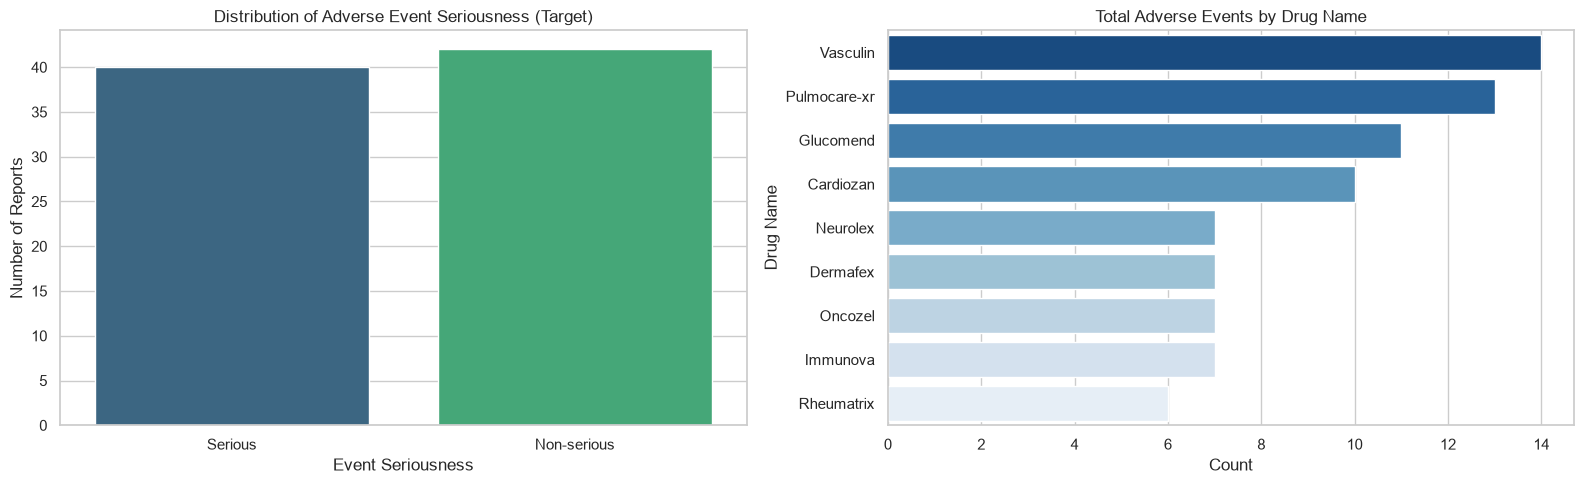

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a professional visual theme
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Target Variable Balance
sns.countplot(data=df, x='EVENT_SERIOUSNESS', palette='viridis', ax=axes[0])
axes[0].set_title('Distribution of Adverse Event Seriousness (Target)')
axes[0].set_xlabel('Event Seriousness')
axes[0].set_ylabel('Number of Reports')

# Plot 2: Drug Volume
sns.countplot(data=df, y='DRUG_NAME', order=df['DRUG_NAME'].value_counts().index, palette='Blues_r', ax=axes[1])
axes[1].set_title('Total Adverse Events by Drug Name')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('Drug Name')

plt.tight_layout()
plt.show()

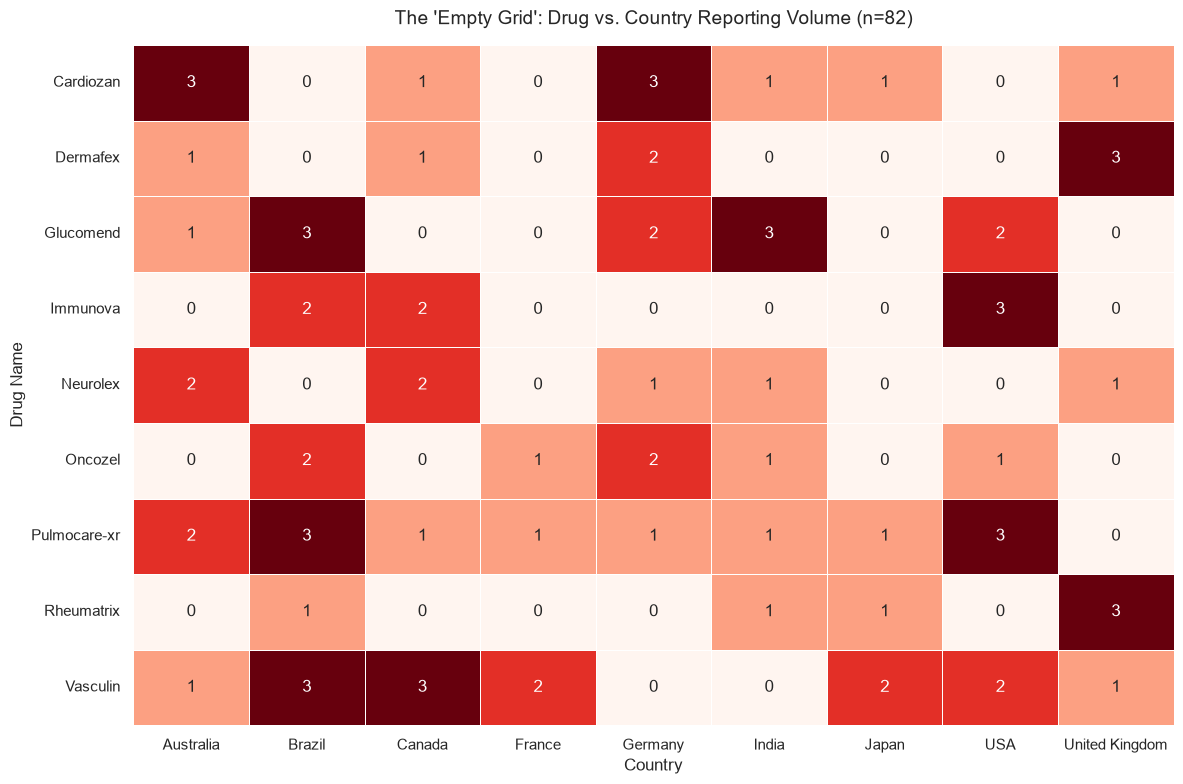

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Create a cross-tabulation grid
sparse_grid = pd.crosstab(df['DRUG_NAME'], df['COUNTRY'])

plt.figure(figsize=(12, 8))
# Plot heatmap. We use annot=True to show the actual numbers (mostly 0s and 1s)
sns.heatmap(sparse_grid, annot=True, cmap="Reds", cbar=False, linewidths=.5, fmt='d')

plt.title("The 'Empty Grid': Drug vs. Country Reporting Volume (n=82)", fontsize=14, pad=15)
plt.xlabel("Country", fontsize=12)
plt.ylabel("Drug Name", fontsize=12)
plt.tight_layout()
plt.show()

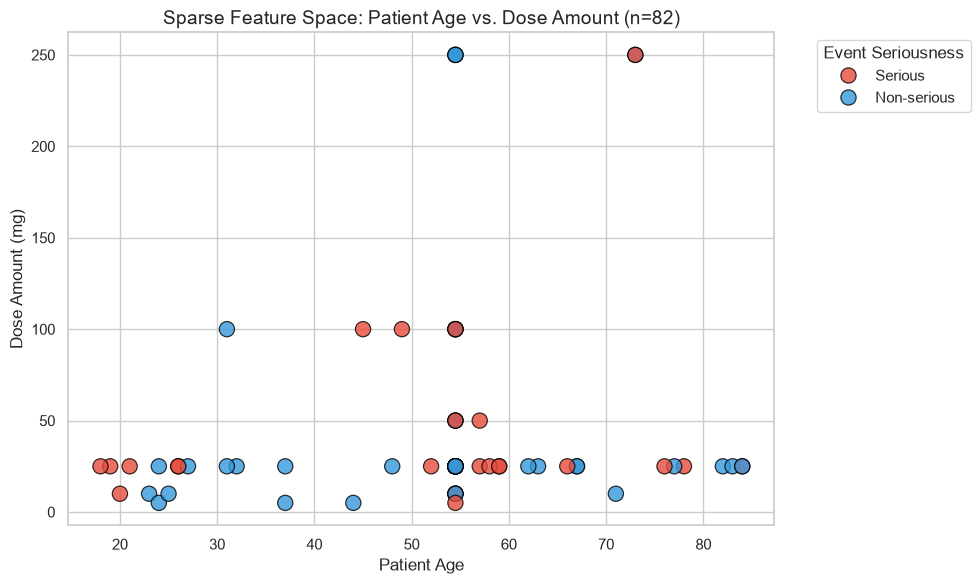

In [7]:
plt.figure(figsize=(10, 6))

# Scatter plot of continuous variables colored by Seriousness
sns.scatterplot(
    data=df, 
    x='PATIENT_AGE', 
    y='DOSE_AMOUNT_MG', 
    hue='EVENT_SERIOUSNESS', 
    palette=['#e74c3c', '#3498db'], # Red for Serious, Blue for Non-Serious
    s=120, # Large dot size
    alpha=0.8,
    edgecolor='black'
)

plt.title("Sparse Feature Space: Patient Age vs. Dose Amount (n=82)", fontsize=14)
plt.xlabel("Patient Age", fontsize=12)
plt.ylabel("Dose Amount (mg)", fontsize=12)

# Move legend outside the plot
plt.legend(title='Event Seriousness', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Task A (Binary Classification)

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc
from xgboost import XGBClassifier
from sklearn.dummy import DummyClassifier
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings

# Suppress warnings for clean output
warnings.filterwarnings('ignore')

# ==========================================
# 1. DATA PREPARATION & STRICT FEATURES
# ==========================================
model_df = df.copy()

# Create Historical AE Frequency if missing
if 'HISTORICAL_AE_FREQUENCY' not in model_df.columns:
    freq_map = model_df['DRUG_NAME'].value_counts().to_dict()
    model_df['HISTORICAL_AE_FREQUENCY'] = model_df['DRUG_NAME'].map(freq_map)

# STRICT FEATURE SELECTION (Prevents Data Leakage)
feature_cols = [
    'PATIENT_AGE', 
    'DRUG_NAME', 
    'DOSE_AMOUNT_MG', 
    'COUNTRY', 
    'REPORTER_TYPE', 
    'BATCH_ID',
    'HISTORICAL_AE_FREQUENCY'
]

# Encode Categorical Features
cat_cols = ['DRUG_NAME', 'COUNTRY', 'REPORTER_TYPE', 'BATCH_ID']
for col in cat_cols:
    if col in model_df.columns:
        le = LabelEncoder()
        model_df[col] = le.fit_transform(model_df[col].astype(str))

# Define X and y (Target: Serious AE)
X = model_df[feature_cols]
y = (model_df['EVENT_SERIOUSNESS'] == 'Serious').astype(int)



In [9]:
# ==========================================
# 2. CROSS-VALIDATION & MODEL SETUP
# ==========================================
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, random_state=42, eval_metric='logloss')
}

cv_summary_results = []
cv_detailed_results = []
roc_data = {}

print("Calculating all CV metrics for strict features (this may take a few seconds)...\n")

# ==========================================
# 3. TRAINING & EVALUATION LOOP
# ==========================================
for name, model in models.items():
    # Calculate detailed cross-validated scores
    acc_scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    prec_scores = cross_val_score(model, X, y, cv=cv, scoring='precision')
    rec_scores = cross_val_score(model, X, y, cv=cv, scoring='recall')
    f1_scores = cross_val_score(model, X, y, cv=cv, scoring='f1')
    
    # Calculate Out-of-fold predictions for ROC-AUC
    y_probs = cross_val_predict(model, X, y, cv=cv, method='predict_proba')[:, 1]
    fpr, tpr, _ = roc_curve(y, y_probs)
    roc_auc = auc(fpr, tpr)
    
    # Store plot data
    roc_data[name] = {'fpr': fpr, 'tpr': tpr, 'auc': roc_auc}
    
    # Store Summary Data (Table 1)
    cv_summary_results.append({
        'Model': name,
        'CV Accuracy': round(acc_scores.mean(), 3),
        'CV F1 Score': round(f1_scores.mean(), 3),
        'CV ROC-AUC': round(roc_auc, 3)
    })
    
    # Store Detailed Data (Table 2)
    cv_detailed_results.append({
        'Model': name,
        'Acc (Mean)': round(acc_scores.mean(), 3),
        'Acc (Std)': round(acc_scores.std(), 3),
        'Prec (Mean)': round(prec_scores.mean(), 3),
        'Prec (Std)': round(prec_scores.std(), 3),
        'Rec (Mean)': round(rec_scores.mean(), 3),
        'Rec (Std)': round(rec_scores.std(), 3),
        'F1 (Mean)': round(f1_scores.mean(), 3),
        'F1 (Std)': round(f1_scores.std(), 3)
    })



Calculating all CV metrics for strict features (this may take a few seconds)...



In [10]:
# ==========================================
# 4. PRINT TABLES & BASELINE
# ==========================================
print("=== Task A: 5-Fold CV Metrics Summary ===")
print(pd.DataFrame(cv_summary_results).to_string(index=False))
print("\n" + "="*85 + "\n")

print("=== Task A: Detailed 5-Fold Cross-Validated Comparison (Mean & Std) ===")
print(pd.DataFrame(cv_detailed_results).to_string(index=False))

# Calculate and print the baseline
dummy = DummyClassifier(strategy='most_frequent')
dummy_scores = cross_val_score(dummy, X, y, cv=cv, scoring='accuracy')
print(f"\nBaseline (majority class) accuracy: {dummy_scores.mean():.3f}\n")



=== Task A: 5-Fold CV Metrics Summary ===
              Model  CV Accuracy  CV F1 Score  CV ROC-AUC
Logistic Regression        0.390        0.345       0.380
      Random Forest        0.547        0.529       0.576
            XGBoost        0.535        0.510       0.556


=== Task A: Detailed 5-Fold Cross-Validated Comparison (Mean & Std) ===
              Model  Acc (Mean)  Acc (Std)  Prec (Mean)  Prec (Std)  Rec (Mean)  Rec (Std)  F1 (Mean)  F1 (Std)
Logistic Regression       0.390      0.064        0.348       0.096       0.350      0.166      0.345     0.131
      Random Forest       0.547      0.072        0.544       0.074       0.525      0.094      0.529     0.067
            XGBoost       0.535      0.093        0.539       0.099       0.525      0.184      0.510     0.120

Baseline (majority class) accuracy: 0.512



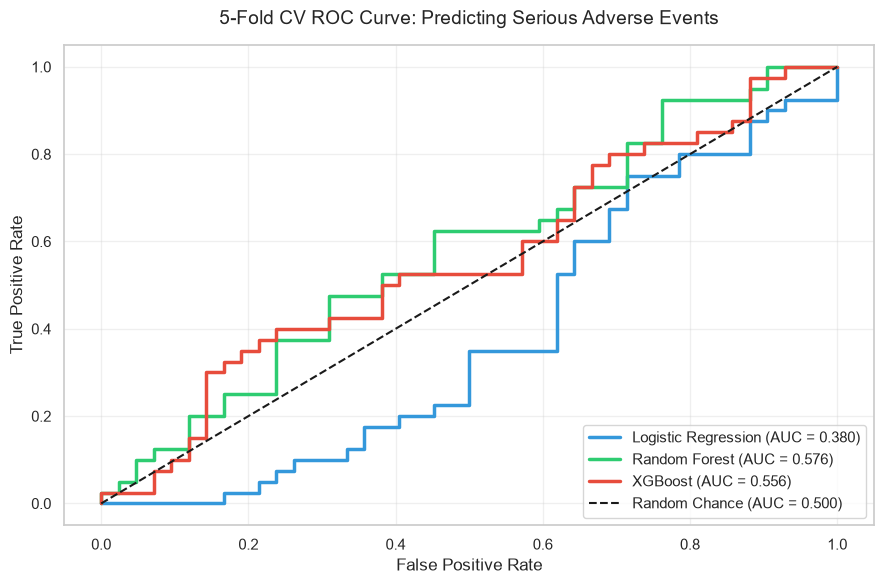

In [11]:
# ==========================================
# 5. PLOT ROC CURVE
# ==========================================
plt.figure(figsize=(9, 6))
colors = ['#3498db', '#2ecc71', '#e74c3c']

for (name, data), color in zip(roc_data.items(), colors):
    plt.plot(data['fpr'], data['tpr'], color=color, linewidth=2.5, 
             label=f"{name} (AUC = {data['auc']:.3f})")

# Add baseline
plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.500)')

# Formatting the Chart
plt.title('5-Fold CV ROC Curve: Predicting Serious Adverse Events', fontsize=14, pad=15)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

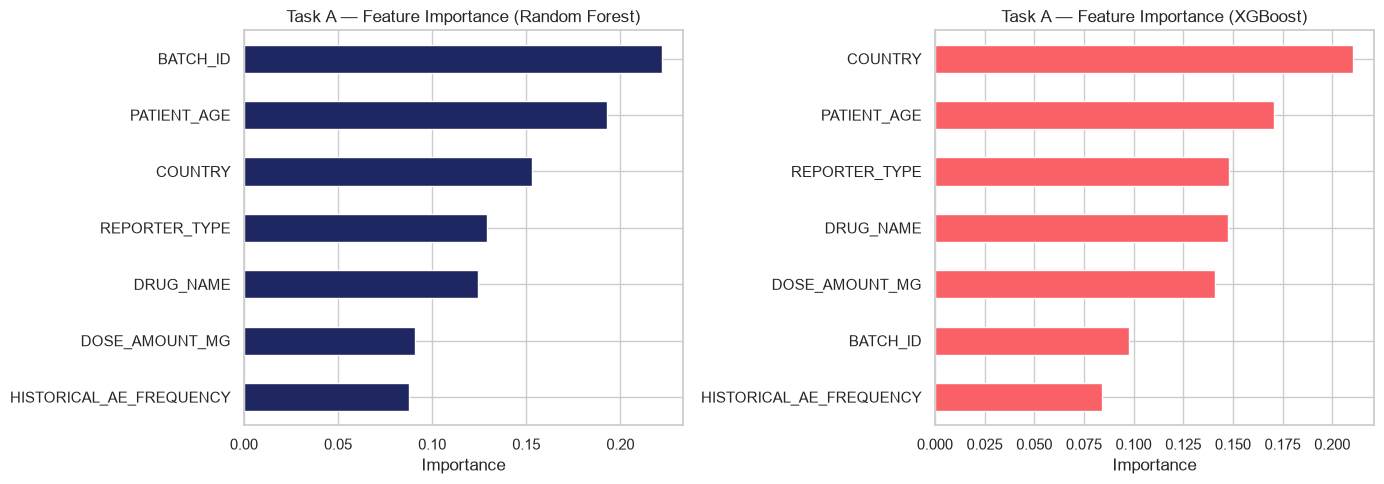

=== Task A: Random Forest Feature Importance ===
BATCH_ID                   0.222152
PATIENT_AGE                0.193095
COUNTRY                    0.152947
REPORTER_TYPE              0.129324
DRUG_NAME                  0.124189
DOSE_AMOUNT_MG             0.090672
HISTORICAL_AE_FREQUENCY    0.087620
dtype: float64

=== Task A: XGBoost Feature Importance ===
COUNTRY                    0.210492
PATIENT_AGE                0.170499
REPORTER_TYPE              0.148064
DRUG_NAME                  0.147676
DOSE_AMOUNT_MG             0.141234
BATCH_ID                   0.097873
HISTORICAL_AE_FREQUENCY    0.084162
dtype: float32


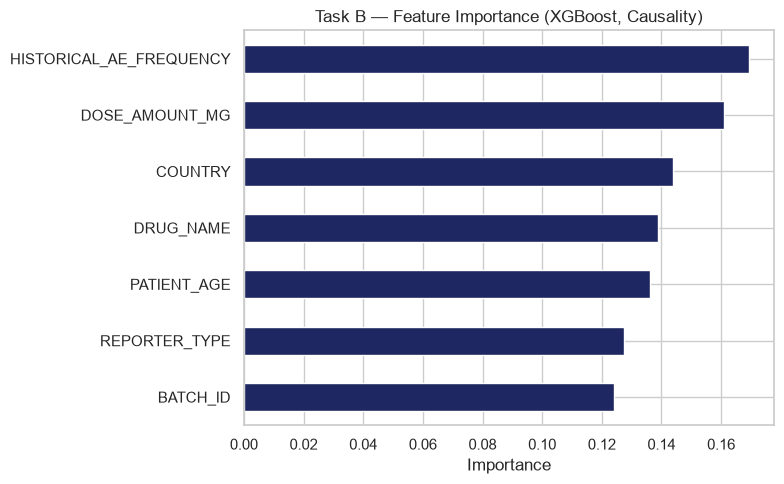


=== Task B: XGBoost Feature Importance ===
HISTORICAL_AE_FREQUENCY    0.169264
DOSE_AMOUNT_MG             0.160859
COUNTRY                    0.143752
DRUG_NAME                  0.138694
PATIENT_AGE                0.136126
REPORTER_TYPE              0.127360
BATCH_ID                   0.123945
dtype: float32

=== Combined Feature Importance Summary ===
                Feature  Task A - Random Forest  Task A - XGBoost  Task B - XGBoost
               BATCH_ID                0.222152          0.097873          0.123945
            PATIENT_AGE                0.193095          0.170499          0.136126
                COUNTRY                0.152947          0.210492          0.143752
          REPORTER_TYPE                0.129324          0.148064          0.127360
              DRUG_NAME                0.124189          0.147676          0.138694
         DOSE_AMOUNT_MG                0.090672          0.141234          0.160859
HISTORICAL_AE_FREQUENCY                0.087620         

In [35]:
# === Feature Importance Analysis — Task A & Task B ===
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# --- Task A: fit final models on full data (cross_val_score never fits the originals) ---
rf_final_a = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)
rf_final_a.fit(X, y)

xgb_final_a = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                             random_state=42, eval_metric='logloss')
xgb_final_a.fit(X, y)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rf_imp = pd.Series(rf_final_a.feature_importances_, index=feature_cols).sort_values(ascending=True)
rf_imp.plot(kind='barh', ax=axes[0], color='#1E2761')
axes[0].set_title('Task A — Feature Importance (Random Forest)')
axes[0].set_xlabel('Importance')

xgb_imp_a = pd.Series(xgb_final_a.feature_importances_, index=feature_cols).sort_values(ascending=True)
xgb_imp_a.plot(kind='barh', ax=axes[1], color='#F96167')
axes[1].set_title('Task A — Feature Importance (XGBoost)')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

print("=== Task A: Random Forest Feature Importance ===")
print(rf_imp.sort_values(ascending=False))
print("\n=== Task A: XGBoost Feature Importance ===")
print(xgb_imp_a.sort_values(ascending=False))

# --- Task B: same fix — fit fresh on full data ---
xgb_final_b = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                             objective='multi:softprob', num_class=len(target_encoder.classes_),
                             random_state=42, eval_metric='mlogloss')
xgb_final_b.fit(X_causality, y_causality)

fig2, ax2 = plt.subplots(figsize=(8, 5))
xgb_imp_b = pd.Series(xgb_final_b.feature_importances_, index=feature_cols).sort_values(ascending=True)
xgb_imp_b.plot(kind='barh', ax=ax2, color='#1E2761')
ax2.set_title('Task B — Feature Importance (XGBoost, Causality)')
ax2.set_xlabel('Importance')
plt.tight_layout()
plt.show()

print("\n=== Task B: XGBoost Feature Importance ===")
print(xgb_imp_b.sort_values(ascending=False))

# --- Combined summary table ---
importance_summary = pd.DataFrame({
    'Feature': feature_cols,
    'Task A - Random Forest': rf_final_a.feature_importances_,
    'Task A - XGBoost': xgb_final_a.feature_importances_,
    'Task B - XGBoost': xgb_final_b.feature_importances_,
}).sort_values('Task A - Random Forest', ascending=False)

print("\n=== Combined Feature Importance Summary ===")
print(importance_summary.to_string(index=False))

### Task B (Multi-Class Classification)

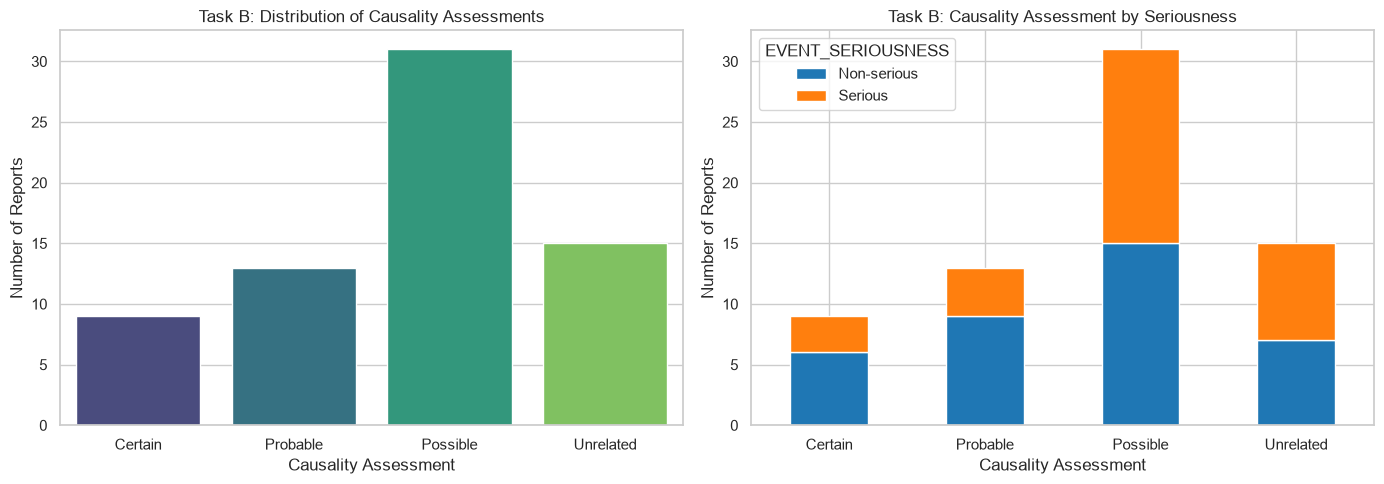

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Target Variable Distribution (Class Imbalance)
causality_order = ['Certain', 'Probable', 'Possible', 'Unrelated']
sns.countplot(
    data=df, 
    x='CAUSALITY_ASSESSMENT', 
    order=causality_order, 
    palette='viridis', 
    ax=axes[0]
)
axes[0].set_title('Task B: Distribution of Causality Assessments')
axes[0].set_xlabel('Causality Assessment')
axes[0].set_ylabel('Number of Reports')

# Plot 2: Causality vs. Seriousness Stacked Bar
crosstab_df = pd.crosstab(df['CAUSALITY_ASSESSMENT'], df['EVENT_SERIOUSNESS'])
# Reorder to match the first plot
crosstab_df = crosstab_df.reindex(causality_order) 
crosstab_df.plot(kind='bar', stacked=True, ax=axes[1], color=['#1f77b4', '#ff7f0e'])

axes[1].set_title('Task B: Causality Assessment by Seriousness')
axes[1].set_xlabel('Causality Assessment')
axes[1].set_ylabel('Number of Reports')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import f1_score, log_loss, confusion_matrix
import pandas as pd
import numpy as np
import warnings

# Suppress warnings for clean output
warnings.filterwarnings('ignore')

# ==========================================
# 1. DATA PREPARATION & STRICT FEATURES
# ==========================================
model_df_b = df.copy()

# Create Historical AE Frequency if missing
if 'HISTORICAL_AE_FREQUENCY' not in model_df_b.columns:
    freq_map = model_df_b['DRUG_NAME'].value_counts().to_dict()
    model_df_b['HISTORICAL_AE_FREQUENCY'] = model_df_b['DRUG_NAME'].map(freq_map)

# STRICT FEATURE SELECTION (Matching Task A)
feature_cols = [
    'PATIENT_AGE', 
    'DRUG_NAME', 
    'DOSE_AMOUNT_MG', 
    'COUNTRY', 
    'REPORTER_TYPE', 
    'BATCH_ID',
    'HISTORICAL_AE_FREQUENCY'
]

# Encode Categorical Features
cat_cols = ['DRUG_NAME', 'COUNTRY', 'REPORTER_TYPE', 'BATCH_ID']
for col in cat_cols:
    if col in model_df_b.columns:
        le = LabelEncoder()
        model_df_b[col] = le.fit_transform(model_df_b[col].astype(str))



In [14]:
# ==========================================
# 2. TARGET ENCODING & MODEL SETUP
# ==========================================
# Encode the Target Variable (Causality Assessment)
target_encoder = LabelEncoder()
y_causality = target_encoder.fit_transform(model_df_b['CAUSALITY_ASSESSMENT'])
X_causality = model_df_b[feature_cols]

# Setup 5-Fold Cross Validation
cv_b = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Initialize Models (Applying class_weight='balanced' to help with minority classes)
models_b = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, 
                             objective='multi:softprob', random_state=42, eval_metric='mlogloss')
}



In [15]:
# ==========================================
# 3. EVALUATION & METRICS OUTPUT
# ==========================================
print("=== Task B: Multi-Class Causality Assessment (Strict Features) ===\n")

for name, model in models_b.items():
    # Generate Out-of-Fold Predictions and Probabilities
    oof_preds = cross_val_predict(model, X_causality, y_causality, cv=cv_b)
    oof_proba = cross_val_predict(model, X_causality, y_causality, cv=cv_b, method='predict_proba')
    
    # Calculate Rubric Metrics
    macro_f1 = f1_score(y_causality, oof_preds, average='macro')
    logloss = log_loss(y_causality, oof_proba)
    cm = confusion_matrix(y_causality, oof_preds)
    
    # Print Results
    print(f"--- {name} ---")
    print(f"F1-score (macro): {macro_f1:.3f}")
    print(f"Log-loss:         {logloss:.3f}")
    print("Confusion Matrix:")
    
    # Format Confusion Matrix with actual class names
    cm_df = pd.DataFrame(cm, index=target_encoder.classes_, columns=target_encoder.classes_)
    print(cm_df)
    print("\n" + "-"*60 + "\n")

=== Task B: Multi-Class Causality Assessment (Strict Features) ===

--- Logistic Regression ---
F1-score (macro): 0.115
Log-loss:         2.067
Confusion Matrix:
           Certain  Possible  Probable  Unlikely  Unrelated
Certain          0         4         4         0          1
Possible         9         3         7         7          5
Probable         4         1         1         4          3
Unlikely         3         3         1         5          2
Unrelated        5         3         2         4          1

------------------------------------------------------------

--- XGBoost ---
F1-score (macro): 0.137
Log-loss:         2.981
Confusion Matrix:
           Certain  Possible  Probable  Unlikely  Unrelated
Certain          0         7         2         0          0
Possible         3        14         5         5          4
Probable         5         6         0         1          1
Unlikely         0         8         1         3          2
Unrelated        1        10     

### Task C (Volume Forecasting)

In [16]:
import pandas as pd
import numpy as np

df['REPORT_RECEIVED_DATE'] = pd.to_datetime(df['REPORT_RECEIVED_DATE'])
df['month'] = df['REPORT_RECEIVED_DATE'].dt.to_period('M').apply(lambda r: r.start_time)

# Aggregate: AE count per drug_name x month
agg_df = df.groupby(['DRUG_NAME', 'month']).size().reset_index(name='ae_count')

# Add features that might explain variance: month number (seasonality), drug identity
agg_df['month_num'] = agg_df['month'].dt.month
agg_df['month_index'] = (agg_df['month'].dt.year - agg_df['month'].dt.year.min()) * 12 + agg_df['month'].dt.month

print(f"Total drug-month groups: {len(agg_df)}")
print(agg_df['ae_count'].describe())
print()
print(agg_df.head(10))

Total drug-month groups: 57
count    57.000000
mean      1.438596
std       0.707550
min       1.000000
25%       1.000000
50%       1.000000
75%       2.000000
max       4.000000
Name: ae_count, dtype: float64

   DRUG_NAME      month  ae_count  month_num  month_index
0  Cardiozan 2025-01-01         1          1            1
1  Cardiozan 2025-02-01         1          2            2
2  Cardiozan 2025-03-01         1          3            3
3  Cardiozan 2025-05-01         1          5            5
4  Cardiozan 2025-07-01         4          7            7
5  Cardiozan 2025-08-01         1          8            8
6  Cardiozan 2025-11-01         1         11           11
7   Dermafex 2025-02-01         2          2            2
8   Dermafex 2025-03-01         2          3            3
9   Dermafex 2025-05-01         1          5            5


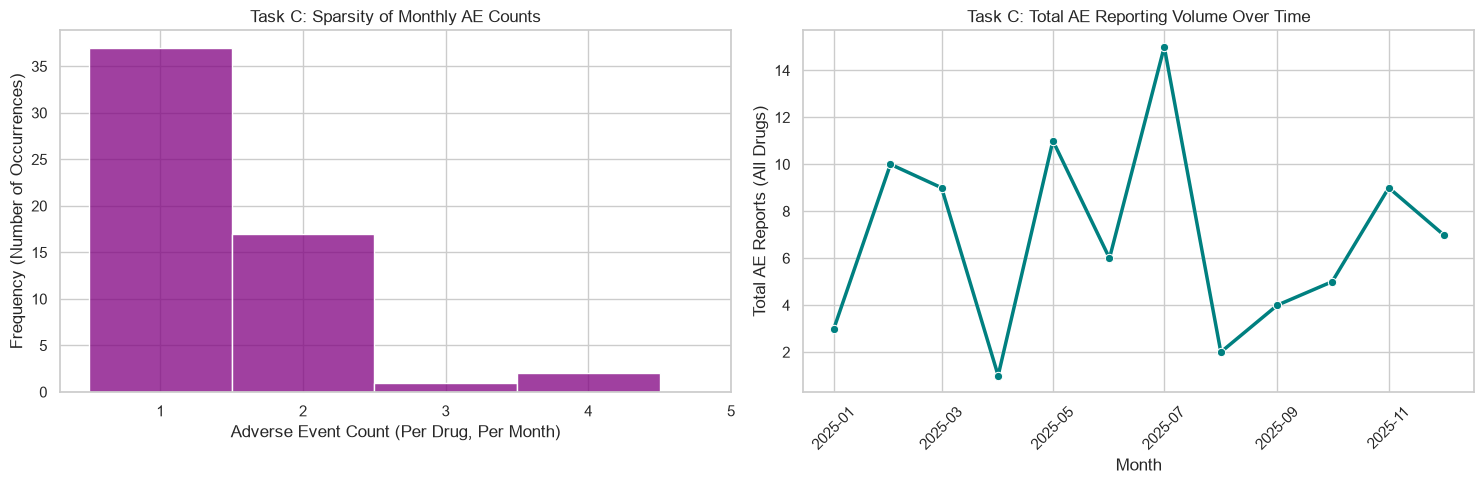

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Histogram of Monthly AE Counts (The Sparsity Problem)
# This shows how many drug-month buckets have 1 event, 2 events, etc.
sns.histplot(
    agg_df['ae_count'], 
    discrete=True, 
    color='purple', 
    ax=axes[0]
)
axes[0].set_title('Task C: Sparsity of Monthly AE Counts')
axes[0].set_xlabel('Adverse Event Count (Per Drug, Per Month)')
axes[0].set_ylabel('Frequency (Number of Occurrences)')
axes[0].set_xticks(range(1, int(agg_df['ae_count'].max()) + 2))

# Plot 2: Total Reporting Volume Over Time
monthly_totals = agg_df.groupby('month')['ae_count'].sum().reset_index()
sns.lineplot(
    data=monthly_totals, 
    x='month', 
    y='ae_count', 
    marker='o', 
    color='teal', 
    linewidth=2.5, 
    ax=axes[1]
)
axes[1].set_title('Task C: Total AE Reporting Volume Over Time')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Total AE Reports (All Drugs)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [18]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import PoissonRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor
import numpy as np

model_df_c = agg_df.copy()
le_drug = LabelEncoder()
model_df_c['drug_encoded'] = le_drug.fit_transform(model_df_c['DRUG_NAME'])

feature_cols_c = ['drug_encoded', 'month_num', 'month_index']
X_c = model_df_c[feature_cols_c]
y_c = model_df_c['ae_count']

print("Target distribution:\n", y_c.value_counts().sort_index())

cv_c = KFold(n_splits=5, shuffle=True, random_state=42)

results_c = []
for name, model in [
    ('Poisson Regression', PoissonRegressor(max_iter=1000)),
    ('XGBoost Regressor', XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.1, random_state=42))
]:
    preds_cv = []
    actuals_cv = []
    for train_idx, test_idx in cv_c.split(X_c):
        model.fit(X_c.iloc[train_idx], y_c.iloc[train_idx])
        p = model.predict(X_c.iloc[test_idx])
        preds_cv.extend(p)
        actuals_cv.extend(y_c.iloc[test_idx])
    rmse = np.sqrt(mean_squared_error(actuals_cv, preds_cv))
    mae = mean_absolute_error(actuals_cv, preds_cv)
    r2 = r2_score(actuals_cv, preds_cv)
    results_c.append({'Model': name, 'CV RMSE': round(rmse,3), 'CV MAE': round(mae,3), 'CV R2': round(r2,3)})

# Baseline: always predict the mean
dummy_c = DummyRegressor(strategy='mean')
dummy_preds, dummy_actuals = [], []
for train_idx, test_idx in cv_c.split(X_c):
    dummy_c.fit(X_c.iloc[train_idx], y_c.iloc[train_idx])
    dummy_preds.extend(dummy_c.predict(X_c.iloc[test_idx]))
    dummy_actuals.extend(y_c.iloc[test_idx])
results_c.append({'Model': 'Baseline (mean predictor)',
                   'CV RMSE': round(np.sqrt(mean_squared_error(dummy_actuals, dummy_preds)),3),
                   'CV MAE': round(mean_absolute_error(dummy_actuals, dummy_preds),3),
                   'CV R2': round(r2_score(dummy_actuals, dummy_preds),3)})

results_c_df = pd.DataFrame(results_c)
print("\n=== Task C: AE Volume Forecasting (drug x month) — CV Results ===")
print(results_c_df.to_string(index=False))

Target distribution:
 ae_count
1    37
2    17
3     1
4     2
Name: count, dtype: int64

=== Task C: AE Volume Forecasting (drug x month) — CV Results ===
                    Model  CV RMSE  CV MAE  CV R2
       Poisson Regression    0.755   0.612 -0.159
        XGBoost Regressor    0.978   0.777 -0.945
Baseline (mean predictor)    0.719   0.578 -0.051


In [19]:
# %%sql -r dataframe_6
# DESCRIBE TABLE PHARMA_CAPSTONE.CURATED.AE_MONTHLY_VOLUME_FIXED;

# Execute the describe query and convert the result directly to a Pandas DataFrame
query_desc = "DESCRIBE TABLE PHARMA_CAPSTONE.CURATED.AE_MONTHLY_VOLUME_FIXED;"
dataframe_6 = session.sql(query_desc).to_pandas()

# Display the dataframe (works in Jupyter notebooks and VS Code interactive windows)
display(dataframe_6)

,"""name""","""type""","""kind""","""null?""","""default""","""primary key""","""unique key""","""check""","""expression""","""comment""","""policy name""","""privacy domain""","""write default"""
0,DRUG_NAME,VARCHAR(16777216),COLUMN,Y,None,N,N,None,None,None,None,None,None
1,MONTH_DATE,DATE,COLUMN,Y,None,N,N,None,None,None,None,None,None
2,AE_COUNT,"NUMBER(38,0)",COLUMN,Y,None,N,N,None,None,None,None,None,None
3,MONTH_NUM,"NUMBER(38,0)",COLUMN,Y,None,N,N,None,None,None,None,None,None
4,MONTH_INDEX,"NUMBER(38,0)",COLUMN,Y,None,N,N,None,None,None,None,None,None


In [20]:
# %%sql -r dataframe_1
# USE ROLE ACCOUNTADMIN;
# USE DATABASE PHARMA_CAPSTONE;
# USE SCHEMA CURATED;

# CREATE OR REPLACE TABLE PHARMA_CAPSTONE.CURATED.AE_MONTHLY_VOLUME_CLEAN AS
# SELECT
#   DRUG_NAME,
#   MONTH_DATE,
#   AE_COUNT
# FROM PHARMA_CAPSTONE.CURATED.AE_MONTHLY_VOLUME_FIXED;

# Set the role, database, and schema context
session.use_role("ACCOUNTADMIN")
session.use_database("PHARMA_CAPSTONE")
session.use_schema("CURATED")

# Execute the query to create the clean monthly volume table
query_create_clean = """
CREATE OR REPLACE TABLE PHARMA_CAPSTONE.CURATED.AE_MONTHLY_VOLUME_CLEAN AS
SELECT
  DRUG_NAME,
  MONTH_DATE,
  AE_COUNT
FROM PHARMA_CAPSTONE.CURATED.AE_MONTHLY_VOLUME_FIXED;
"""

dataframe_1 = session.sql(query_create_clean).collect()
print("Table AE_MONTHLY_VOLUME_CLEAN created successfully!")

Table AE_MONTHLY_VOLUME_CLEAN created successfully!


In [21]:
# %%sql -r dataframe_4
# DROP SNOWFLAKE.ML.FORECAST IF EXISTS ae_volume_forecast_model;

# CREATE OR REPLACE SNOWFLAKE.ML.FORECAST ae_volume_forecast_model(
#   INPUT_DATA => TABLE(PHARMA_CAPSTONE.CURATED.AE_MONTHLY_VOLUME_CLEAN),
#   SERIES_COLNAME => 'DRUG_NAME',
#   TIMESTAMP_COLNAME => 'MONTH_DATE',
#   TARGET_COLNAME => 'AE_COUNT'
# );

# Drop the model if it already exists
query_drop = "DROP SNOWFLAKE.ML.FORECAST IF EXISTS ae_volume_forecast_model;"
session.sql(query_drop).collect()

# Create the Snowflake ML Forecast model
query_create_forecast_model = """
CREATE OR REPLACE SNOWFLAKE.ML.FORECAST ae_volume_forecast_model(
    INPUT_DATA => TABLE(PHARMA_CAPSTONE.CURATED.AE_MONTHLY_VOLUME_CLEAN),
    SERIES_COLNAME => 'DRUG_NAME',
    TIMESTAMP_COLNAME => 'MONTH_DATE',
    TARGET_COLNAME => 'AE_COUNT'
);
"""

dataframe_4 = session.sql(query_create_forecast_model).collect()
print("Forecast model ae_volume_forecast_model created successfully!")

Forecast model ae_volume_forecast_model created successfully!


In [22]:
# %%sql -r dataframe_5
# CALL ae_volume_forecast_model!FORECAST(FORECASTING_PERIODS => 3);

# Call the forecast model to predict the next 3 periods and convert to a Pandas DataFrame
query_forecast_call = "CALL ae_volume_forecast_model!FORECAST(FORECASTING_PERIODS => 3);"
dataframe_5 = session.sql(query_forecast_call).to_pandas()

# Display the results
display(dataframe_5)

,"""SERIES""","""TS""","""FORECAST""","""LOWER_BOUND""","""UPPER_BOUND"""
0,"""Pulmocare-xr""",2026-01-01,1.000000,-0.385904,2.385904
1,"""Pulmocare-xr""",2026-03-01,1.000000,-0.959964,2.959964
2,"""Pulmocare-xr""",2026-05-01,1.000000,-1.400456,3.400456
3,"""Oncozel""",2026-02-15,2.000000,1.020018,2.979982
4,"""Oncozel""",2026-05-01,2.000000,0.614096,3.385904
5,"""Oncozel""",2026-07-15,2.000000,0.302621,3.697379
6,"""Neurolex""",2026-05-20,1.500000,0.807048,2.192952
7,"""Neurolex""",2026-11-04,1.500000,0.520018,2.479982
8,"""Neurolex""",2027-04-21,1.500000,0.299772,2.700228
9,"""Glucomend""",2026-01-01,1.502505,1.222436,1.821590


In [31]:
# CREATE OR REPLACE TABLE PHARMA_CAPSTONE.CURATED.AE_VOLUME_FORECAST_SCORES AS
# SELECT * FROM TABLE(RESULT_SCAN(LAST_QUERY_ID()));

# Execute the SQL statement to create the table from the last query result
session.sql("""
    CREATE OR REPLACE TABLE PHARMA_CAPSTONE.CURATED.AE_VOLUME_FORECAST_SCORES AS
    SELECT * FROM TABLE(RESULT_SCAN(LAST_QUERY_ID()))
""").collect()

[Row(status='Table AE_VOLUME_FORECAST_SCORES successfully created.')]

### Task D (Anomaly Detection)

In [23]:
import pandas as pd

# 1. Standardize dates
df['REPORT_RECEIVED_DATE'] = pd.to_datetime(df['REPORT_RECEIVED_DATE'])
df['week'] = df['REPORT_RECEIVED_DATE'].dt.to_period('W').apply(lambda r: r.start_time)

# 2. Get the base sparse counts
weekly_agg = df.groupby(['DRUG_NAME', 'BATCH_ID', 'week']).size().reset_index(name='ae_count')
weekly_agg['drug_batch'] = weekly_agg['DRUG_NAME'] + '_' + weekly_agg['BATCH_ID'].astype(str)

# 3. THE FIX: Create a complete grid of all batches across all active weeks
all_batches = weekly_agg['drug_batch'].unique()
all_weeks = weekly_agg['week'].unique()

# Generate every combination
multi_idx = pd.MultiIndex.from_product([all_batches, all_weeks], names=['drug_batch', 'week'])
dense_df = pd.DataFrame(index=multi_idx).reset_index()

# Merge our actual counts into the grid and fill missing weeks with 0
merged = pd.merge(dense_df, weekly_agg[['drug_batch', 'week', 'ae_count']], on=['drug_batch', 'week'], how='left')
merged['ae_count'] = merged['ae_count'].fillna(0).astype(int)
merged['week'] = merged['week'].astype(str)

print(f"Total zero-filled drug-batch-week rows: {len(merged)}")
print(merged['ae_count'].value_counts())

# 4. Push to Snowflake
session.use_database("PHARMA_CAPSTONE")
session.use_schema("CURATED")

snowpark_weekly = session.create_dataframe(merged)
snowpark_weekly.write.mode("overwrite").save_as_table("PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_BATCH_RAW")
print("Dense dataset pushed to PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_BATCH_RAW")

Total zero-filled drug-batch-week rows: 3160
ae_count
0    3079
1      80
2       1
Name: count, dtype: int64
Dense dataset pushed to PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_BATCH_RAW


In [24]:
import pandas as pd

# 1. Aggregate weekly counts and standardize column names
weekly_agg2 = df.groupby(['DRUG_NAME', 'week']).size().reset_index(name='ae_count')
weekly_agg2['week'] = pd.to_datetime(weekly_agg2['week']).dt.strftime('%Y-%m-%d')

# 2. Push directly to a clean Snowflake table
snowpark_weekly2 = session.create_dataframe(weekly_agg2)
snowpark_weekly2.write.mode("overwrite").save_as_table("PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_CLEAN_FIXED")
print("Clean weekly table created successfully!")

Clean weekly table created successfully!


In [25]:
# USE ROLE ACCOUNTADMIN;
# USE DATABASE PHARMA_CAPSTONE;
# USE SCHEMA CURATED;

# -- 1. Create a clean base weekly table directly in Snowflake
# CREATE OR REPLACE TABLE PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_DIRECT AS
# SELECT 
#     d.DRUG_NAME,
#     DATE_TRUNC('week', dt_recv.FULL_DATE) AS WEEK_DATE,
#     COUNT(*) AS AE_COUNT
# FROM PHARMA_CAPSTONE.CURATED.FACT_AE_REPORT f
# LEFT JOIN PHARMA_CAPSTONE.CURATED.DIM_DRUG d ON f.DRUG_KEY = d.DRUG_KEY
# LEFT JOIN PHARMA_CAPSTONE.CURATED.DIM_DATE dt_recv ON f.RECEIVED_DATE_KEY = dt_recv.DATE_KEY
# GROUP BY d.DRUG_NAME, DATE_TRUNC('week', dt_recv.FULL_DATE);

# -- 2. Create Training View (Everything before September)
# CREATE OR REPLACE VIEW PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_TRAIN AS
# SELECT DRUG_NAME, WEEK_DATE, AE_COUNT 
# FROM PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_DIRECT
# WHERE WEEK_DATE < '2025-09-01';

# -- 3. Create Detection View (September onward, which includes our target spike)
# CREATE OR REPLACE VIEW PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_DETECT AS
# SELECT DRUG_NAME, WEEK_DATE, AE_COUNT 
# FROM PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_DIRECT
# WHERE WEEK_DATE >= '2025-09-01';

# -- 4. Build and Train the Model strictly on the Training View
# DROP SNOWFLAKE.ML.ANOMALY_DETECTION IF EXISTS ae_signal_model_drug;

# CREATE OR REPLACE SNOWFLAKE.ML.ANOMALY_DETECTION ae_signal_model_drug(
#   INPUT_DATA => TABLE(PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_TRAIN),
#   SERIES_COLNAME => 'DRUG_NAME',
#   TIMESTAMP_COLNAME => 'WEEK_DATE',
#   TARGET_COLNAME => 'AE_COUNT',
#   LABEL_COLNAME => ''
# );

# -- 5. Call DETECT_ANOMALIES with the full signature on the Detection View
# CALL ae_signal_model_drug!DETECT_ANOMALIES(
#   INPUT_DATA => TABLE(PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_DETECT),
#   SERIES_COLNAME => 'DRUG_NAME',
#   TIMESTAMP_COLNAME => 'WEEK_DATE',
#   TARGET_COLNAME => 'AE_COUNT',
#   CONFIG_OBJECT => {'prediction_interval': 0.95}
# );

# -- 6. Save the results to a table
# CREATE OR REPLACE TABLE PHARMA_CAPSTONE.CURATED.AE_SIGNAL_FLAGS AS
# SELECT * FROM TABLE(RESULT_SCAN(LAST_QUERY_ID()));

# -- 7. Sanity Check Summary
# SELECT IS_ANOMALY, COUNT(*) 
# FROM PHARMA_CAPSTONE.CURATED.AE_SIGNAL_FLAGS 
# GROUP BY IS_ANOMALY;

# -- 8. View the exact detected anomalies sorted by timestamp
# SELECT * FROM PHARMA_CAPSTONE.CURATED.AE_SIGNAL_FLAGS
# WHERE IS_ANOMALY = TRUE
# ORDER BY TS;

In [26]:
# Set the context
session.use_role("ACCOUNTADMIN")
session.use_database("PHARMA_CAPSTONE")
session.use_schema("CURATED")

# 1. Create a clean base weekly table directly in Snowflake
query_create_direct_table = """
CREATE OR REPLACE TABLE PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_DIRECT AS
SELECT 
    d.DRUG_NAME,
    DATE_TRUNC('week', dt_recv.FULL_DATE) AS WEEK_DATE,
    COUNT(*) AS AE_COUNT
FROM PHARMA_CAPSTONE.CURATED.FACT_AE_REPORT f
LEFT JOIN PHARMA_CAPSTONE.CURATED.DIM_DRUG d ON f.DRUG_KEY = d.DRUG_KEY
LEFT JOIN PHARMA_CAPSTONE.CURATED.DIM_DATE dt_recv ON f.RECEIVED_DATE_KEY = dt_recv.DATE_KEY
GROUP BY d.DRUG_NAME, DATE_TRUNC('week', dt_recv.FULL_DATE);
"""
session.sql(query_create_direct_table).collect()

# 2. Create Training View (Everything before September)
query_train_view = """
CREATE OR REPLACE VIEW PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_TRAIN AS
SELECT DRUG_NAME, WEEK_DATE, AE_COUNT 
FROM PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_DIRECT
WHERE WEEK_DATE < '2025-09-01';
"""
session.sql(query_train_view).collect()

# 3. Create Detection View (September onward, which includes our target spike)
query_detect_view = """
CREATE OR REPLACE VIEW PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_DETECT AS
SELECT DRUG_NAME, WEEK_DATE, AE_COUNT 
FROM PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_DIRECT
WHERE WEEK_DATE >= '2025-09-01';
"""
session.sql(query_detect_view).collect()

# 4. Build and Train the Model strictly on the Training View
session.sql("DROP SNOWFLAKE.ML.ANOMALY_DETECTION IF EXISTS ae_signal_model_drug;").collect()

query_create_model = """
CREATE OR REPLACE SNOWFLAKE.ML.ANOMALY_DETECTION ae_signal_model_drug(
  INPUT_DATA => TABLE(PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_TRAIN),
  SERIES_COLNAME => 'DRUG_NAME',
  TIMESTAMP_COLNAME => 'WEEK_DATE',
  TARGET_COLNAME => 'AE_COUNT',
  LABEL_COLNAME => ''
);
"""
session.sql(query_create_model).collect()

# 5. Call DETECT_ANOMALIES with the full signature on the Detection View
query_detect_call = """
CALL ae_signal_model_drug!DETECT_ANOMALIES(
  INPUT_DATA => TABLE(PHARMA_CAPSTONE.CURATED.AE_WEEKLY_DRUG_DETECT),
  SERIES_COLNAME => 'DRUG_NAME',
  TIMESTAMP_COLNAME => 'WEEK_DATE',
  TARGET_COLNAME => 'AE_COUNT',
  CONFIG_OBJECT => {'prediction_interval': 0.95}
);
"""
session.sql(query_detect_call).collect()

# 6. Save the results to a table using LAST_QUERY_ID()
query_save_results = """
CREATE OR REPLACE TABLE PHARMA_CAPSTONE.CURATED.AE_SIGNAL_FLAGS AS
SELECT * FROM TABLE(RESULT_SCAN(LAST_QUERY_ID()));
"""
session.sql(query_save_results).collect()

# 7. Sanity Check Summary
query_sanity_check = """
SELECT IS_ANOMALY, COUNT(*) 
FROM PHARMA_CAPSTONE.CURATED.AE_SIGNAL_FLAGS 
GROUP BY IS_ANOMALY;
"""
dataframe_sanity = session.sql(query_sanity_check).to_pandas()
print("=== Sanity Check Summary ===")
display(dataframe_sanity)

# 8. View the exact detected anomalies sorted by timestamp
query_show_anomalies = """
SELECT * FROM PHARMA_CAPSTONE.CURATED.AE_SIGNAL_FLAGS
WHERE IS_ANOMALY = TRUE
ORDER BY TS;
"""
dataframe_anomalies = session.sql(query_show_anomalies).to_pandas()
print("=== Detected Anomalies ===")
display(dataframe_anomalies)

=== Sanity Check Summary ===


,IS_ANOMALY,COUNT(*)
0,True,3
1,False,19


=== Detected Anomalies ===


,SERIES,TS,Y,FORECAST,LOWER_BOUND,UPPER_BOUND,IS_ANOMALY,PERCENTILE,DISTANCE
0,"""Immunova""",2025-09-15,2.0,1.0,1.000000,1.000000,True,1.000000,inf
1,"""Vasculin""",2025-11-03,2.0,1.0,0.374702,1.625298,True,0.999139,3.134447
2,"""Oncozel""",2025-12-08,2.0,1.0,1.000000,1.000000,True,1.000000,inf


=== CLINICAL CAUSALITY VS STATISTICAL ANOMALY ===

Statistical Spike Detected: Immunova (Week of 2025-09-15) | Total Reports: 2
   REPORT_ID EVENT_SERIOUSNESS CAUSALITY_ASSESSMENT
AE-2025-0021       Non-serious            Unrelated
AE-2025-0021       Non-serious            Unrelated

Statistical Spike Detected: Vasculin (Week of 2025-11-03) | Total Reports: 2
   REPORT_ID EVENT_SERIOUSNESS CAUSALITY_ASSESSMENT
AE-2025-0060           Serious             Possible
AE-2025-0009           Serious              Certain

Statistical Spike Detected: Oncozel (Week of 2025-12-08) | Total Reports: 2
   REPORT_ID EVENT_SERIOUSNESS CAUSALITY_ASSESSMENT
AE-2025-0022       Non-serious            Unrelated
AE-2025-0050       Non-serious              Certain


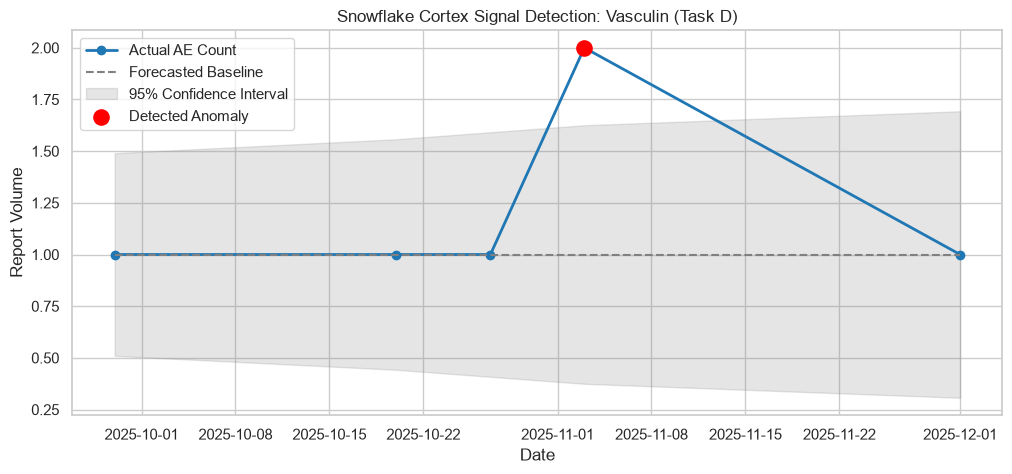

In [27]:
import pandas as pd

# The 3 statistical anomalies detected by Snowflake Cortex
anomalies = [
    {"drug": "Immunova", "week": "2025-09-15"},
    {"drug": "Vasculin", "week": "2025-11-03"},
    {"drug": "Oncozel", "week": "2025-12-08"}
]

print("=== CLINICAL CAUSALITY VS STATISTICAL ANOMALY ===")
for a in anomalies:
    # Filter the original dataframe for the specific drug and week
    spike_reports = df[(df['DRUG_NAME'] == a['drug']) & (df['week'].astype(str) == a['week'])]
    
    print(f"\nStatistical Spike Detected: {a['drug']} (Week of {a['week']}) | Total Reports: {len(spike_reports)}")
    print(spike_reports[['REPORT_ID', 'EVENT_SERIOUSNESS', 'CAUSALITY_ASSESSMENT']].to_string(index=False))

# Pull the Anomaly data from Snowflake back into Pandas
flags_query = "SELECT * FROM PHARMA_CAPSTONE.CURATED.AE_SIGNAL_FLAGS ORDER BY TS"
flags_df = session.sql(flags_query).to_pandas()
flags_df['TS'] = pd.to_datetime(flags_df['TS'])

# Clean up the SERIES column (Snowflake sometimes adds double quotes)
flags_df['SERIES_CLEAN'] = flags_df['SERIES'].str.replace('"', '')

# Isolate the Vasculin timeline to show the exact spike we found
vasculin_data = flags_df[flags_df['SERIES_CLEAN'] == 'Vasculin']

plt.figure(figsize=(12, 5))

# Plot Actuals, Forecasts, and the Confidence Interval
plt.plot(vasculin_data['TS'], vasculin_data['Y'], marker='o', label='Actual AE Count', color='#1f77b4', linewidth=2)
plt.plot(vasculin_data['TS'], vasculin_data['FORECAST'], linestyle='--', label='Forecasted Baseline', color='gray')
plt.fill_between(vasculin_data['TS'], vasculin_data['LOWER_BOUND'], vasculin_data['UPPER_BOUND'], color='gray', alpha=0.2, label='95% Confidence Interval')

# Draw a red dot over the detected anomalies
anomalies = vasculin_data[vasculin_data['IS_ANOMALY'] == True]
plt.scatter(anomalies['TS'], anomalies['Y'], color='red', s=120, zorder=5, label='Detected Anomaly')

plt.title('Snowflake Cortex Signal Detection: Vasculin (Task D)')
plt.xlabel('Date')
plt.ylabel('Report Volume')
plt.legend()
plt.show()

In [28]:
# Fit final model on full data for scoring (already validated via CV above)
final_model_a = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                                random_state=42, eval_metric='logloss')
final_model_a.fit(X, y)

scores_a = df[['REPORT_ID']].copy()
scores_a['ACTUAL_SERIOUSNESS'] = df['EVENT_SERIOUSNESS']
scores_a['PREDICTED_SERIOUSNESS'] = final_model_a.predict(X)
scores_a['PREDICTED_SERIOUSNESS'] = scores_a['PREDICTED_SERIOUSNESS'].map({1: 'Serious', 0: 'Non-serious'})
scores_a['PREDICTED_PROBABILITY'] = final_model_a.predict_proba(X)[:, 1]

session.use_database("PHARMA_CAPSTONE")
session.use_schema("CURATED")
snowpark_scores_a = session.create_dataframe(scores_a)
snowpark_scores_a.write.mode("overwrite").save_as_table("PHARMA_CAPSTONE.CURATED.AE_PREDICTIONS_SERIOUSNESS")
print("Saved AE_PREDICTIONS_SERIOUSNESS")

Saved AE_PREDICTIONS_SERIOUSNESS


In [29]:
scores_b = model_df_b[['REPORT_ID']].copy() if 'REPORT_ID' in model_df_b.columns else df[['REPORT_ID']].copy()
scores_b['ACTUAL_CAUSALITY'] = target_encoder.inverse_transform(y_causality)
scores_b['PREDICTED_CAUSALITY'] = target_encoder.inverse_transform(oof_preds)

session.use_database("PHARMA_CAPSTONE")
session.use_schema("CURATED")
snowpark_scores_b = session.create_dataframe(scores_b)
snowpark_scores_b.write.mode("overwrite").save_as_table("PHARMA_CAPSTONE.CURATED.AE_PREDICTIONS_CAUSALITY")
print("Saved AE_PREDICTIONS_CAUSALITY")

Saved AE_PREDICTIONS_CAUSALITY


In [32]:
# === Display all 4 batch scoring / output tables ===
session.use_database("PHARMA_CAPSTONE")
session.use_schema("CURATED")

tables_to_check = [
    "AE_PREDICTIONS_SERIOUSNESS",   # Task A
    "AE_PREDICTIONS_CAUSALITY",     # Task B
    "AE_VOLUME_FORECAST_SCORES",    # Task C
    "AE_SIGNAL_FLAGS"               # Task D
]

for tbl in tables_to_check:
    print(f"\n=== {tbl} ===")
    try:
        result_df = session.sql(f"SELECT * FROM PHARMA_CAPSTONE.CURATED.{tbl} LIMIT 10").to_pandas()
        count = session.sql(f"SELECT COUNT(*) AS ROW_COUNT FROM PHARMA_CAPSTONE.CURATED.{tbl}").to_pandas()
        print(f"Row count: {count['ROW_COUNT'].iloc[0]}")
        display(result_df)
    except Exception as e:
        print(f"Could not load {tbl}: {e}")


=== AE_PREDICTIONS_SERIOUSNESS ===
Row count: 82


,REPORT_ID,ACTUAL_SERIOUSNESS,PREDICTED_SERIOUSNESS,PREDICTED_PROBABILITY
0,AE-2025-0001,Serious,Serious,0.893634
1,AE-2025-0018,Serious,Serious,0.856599
2,AE-2025-0059,Serious,Serious,0.947306
3,AE-2025-0027,Serious,Serious,0.985384
4,AE-2025-0032,Non-serious,Non-serious,0.152069
5,AE-2025-0057,Non-serious,Non-serious,0.002054
6,AE-2025-0015,Serious,Serious,0.764886
7,AE-2025-0012,Non-serious,Non-serious,0.198206
8,AE-2025-0075,Serious,Serious,0.976152
9,AE-2025-0037,Serious,Serious,0.736201



=== AE_PREDICTIONS_CAUSALITY ===
Row count: 82


,REPORT_ID,ACTUAL_CAUSALITY,PREDICTED_CAUSALITY
0,AE-2025-0001,Probable,Possible
1,AE-2025-0018,Unlikely,Possible
2,AE-2025-0059,Unlikely,Unlikely
3,AE-2025-0027,Unlikely,Possible
4,AE-2025-0032,Possible,Possible
5,AE-2025-0057,Possible,Unrelated
6,AE-2025-0015,Possible,Probable
7,AE-2025-0012,Unlikely,Possible
8,AE-2025-0075,Unrelated,Possible
9,AE-2025-0037,Certain,Possible



=== AE_VOLUME_FORECAST_SCORES ===
Row count: 1


,status
0,Table AE_PREDICTIONS_CAUSALITY successfully cr...



=== AE_SIGNAL_FLAGS ===
Row count: 22


,SERIES,TS,Y,FORECAST,LOWER_BOUND,UPPER_BOUND,IS_ANOMALY,PERCENTILE,DISTANCE
0,"""Neurolex""",2025-11-24,1.0,1.5,0.520018,2.479982,False,0.158655,-1.000000
1,"""Neurolex""",2025-12-08,1.0,1.5,0.520018,2.479982,False,0.158655,-1.000000
2,"""Neurolex""",2025-12-29,1.0,1.5,0.520018,2.479982,False,0.158655,-1.000000
3,"""Oncozel""",2025-10-06,1.0,1.0,1.000000,1.000000,False,NaN,NaN
4,"""Oncozel""",2025-12-08,2.0,1.0,1.000000,1.000000,True,1.000000,inf
5,"""Glucomend""",2025-11-10,1.0,1.5,0.705219,2.294781,False,0.108784,-1.233021
6,"""Glucomend""",2025-11-17,1.0,1.5,0.699848,2.300152,False,0.110336,-1.224745
7,"""Glucomend""",2025-12-22,1.0,1.5,0.699848,2.300152,False,0.110336,-1.224745
8,"""Dermafex""",2025-11-10,1.0,1.0,0.307048,1.692952,False,0.500000,0.000000
9,"""Pulmocare-xr""",2025-09-01,1.0,1.0,0.105153,1.894847,False,0.500000,0.000000
